<a href="https://colab.research.google.com/github/jbakkiyanathan/AAI500_Breast_Cancer_Analysis/blob/main/Team_1_Final_Project_AAI500_Buffy_Barentine_Key_Findings_Forest_Plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 14.9 MB/s eta 0:00:00


In [2]:
import pandas as pd

# Direct read into Pandas
url = "https://raw.githubusercontent.com/jbakkiyanathan/AAI500_Breast_Cancer_Analysis/refs/heads/main/Breast_Cancer_METABRIC_Epic_Hospital.csv"
df = pd.read_csv(url)

In [3]:
# Check shape (rows, columns) and preview the first 3 rows
print("Shape:", df.shape)
df.head(3)

Shape: (15054, 34)


,Patient ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,...,Overall Survival Status,PR Status,Radio Therapy,Relapse Free Status (Months),Relapse Free Status,Sex,3-Gene classifier subtype,Tumor Size,Tumor Stage,Patient's Vital Status
0,MB-0000,75.65,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,claudin-low,1.0,Positve,...,Living,Negative,Yes,138.65,Not Recurred,Female,ER+/HER2- High Prolif,22.0,2.0,Living
1,MB-0002,43.19,Breast Conserving,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,LumA,1.0,Positve,...,Living,Positive,Yes,83.52,Not Recurred,Female,ER+/HER2- High Prolif,10.0,1.0,Living
2,MB-0005,48.87,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,Yes,LumB,1.0,Positve,...,Deceased,Positive,No,151.28,Recurred,Female,ER+/HER2- High Prolif,15.0,2.0,Died of Disease


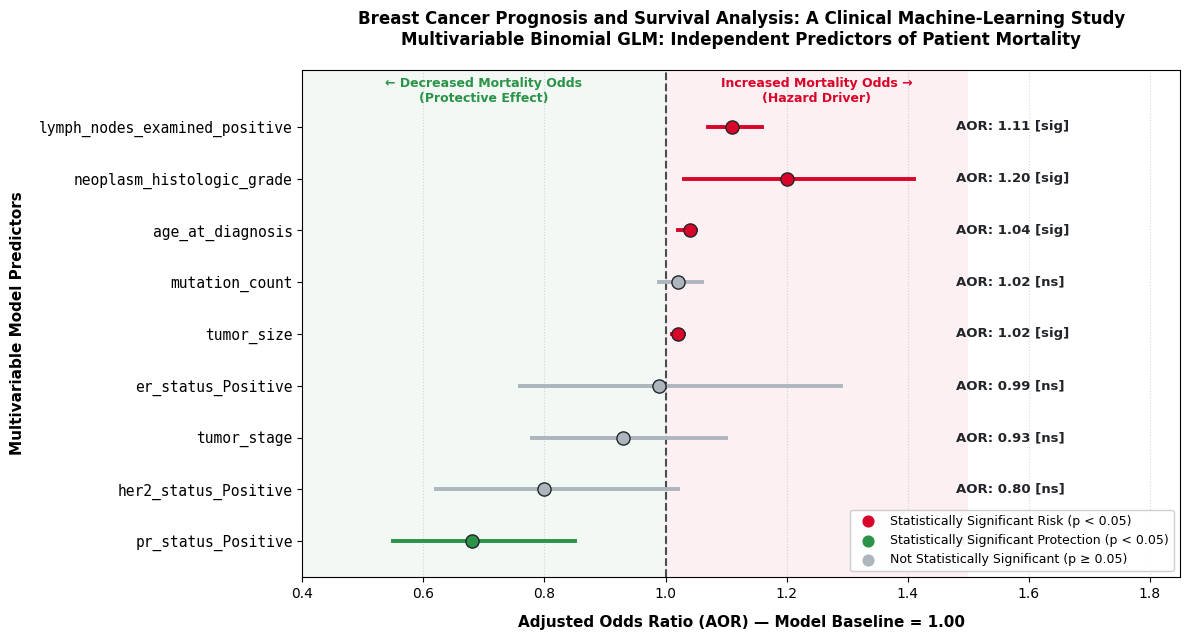

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Exact variable/vector names directly from your paper and datasets
factors = [
    'lymph_nodes_examined_positive',
    'neoplasm_histologic_grade',
    'age_at_diagnosis',
    'mutation_count',
    'tumor_size',
    'er_status_Positive',
    'tumor_stage',
    'her2_status_Positive',
    'pr_status_Positive'
]

odds_ratios = [1.11, 1.20, 1.04, 1.02, 1.02, 0.99, 0.93, 0.80, 0.68]
p_values    = [0.0001, 0.0234, 0.0001, 0.0892, 0.0001, 0.9431, 0.3726, 0.0749, 0.0007]

# Matched confidence intervals
ci_low  = [1.07, 1.03, 1.02, 0.99, 1.01, 0.76, 0.78, 0.62, 0.55]
ci_high = [1.16, 1.41, 1.05, 1.06, 1.03, 1.29, 1.10, 1.02, 0.85]

y_pos = np.arange(len(factors))

# 2. Canvas adjustments with right margins for text
fig, ax = plt.subplots(figsize=(12, 6.5))

# Reference baseline: OR = 1.0 (No Effect)
ax.axvline(1.0, color='#212529', linestyle='--', linewidth=1.5, alpha=0.8, zorder=2)

# Color assignment
colors = []
for or_val, p in zip(odds_ratios, p_values):
    if p < 0.05 and or_val > 1.0:
        colors.append('#D90429')  # Hazard (Red)
    elif p < 0.05 and or_val < 1.0:
        colors.append('#2B9348')  # Protective (Green)
    else:
        colors.append('#ADB5BD')  # Non-Significant (Gray)

# 3. Render markers, intervals, and shortened text (no stars/long decimals)
for i in range(len(factors)):
    ax.plot([ci_low[i], ci_high[i]], [y_pos[i], y_pos[i]], color=colors[i], lw=2.8, zorder=3)
    ax.scatter(odds_ratios[i], y_pos[i], color=colors[i], s=90, edgecolors='#212529', zorder=4)

    # Simplify label to AOR & significance only (e.g., AOR: 1.11 [sig])
    sig_label = "[sig]" if p_values[i] < 0.05 else "[ns]"
    stat_text = f"AOR: {odds_ratios[i]:.2f} {sig_label}"

    # Text is placed safely near the visual boundaries
    ax.text(1.48, y_pos[i], stat_text, va='center', ha='left', fontsize=9.5,
            fontweight='bold', color='#212529', zorder=5)

# 4. Lightly shaded background zones
ax.axvspan(0.40, 1.00, facecolor='#2B9348', alpha=0.06, zorder=1)
ax.axvspan(1.00, 1.50, facecolor='#D90429', alpha=0.06, zorder=1)

# Annotations (Z-values)
ax.text(0.70, -0.7, "← Decreased Mortality Odds\n(Protective Effect)", ha='center', va='center',
        fontsize=9, fontweight='bold', color='#2B9348')
ax.text(1.25, -0.7, "Increased Mortality Odds →\n(Hazard Driver)", ha='center', va='center',
        fontsize=9, fontweight='bold', color='#D90429')

# 5. Labels & Title
ax.set_yticks(y_pos)
ax.set_yticklabels(factors, fontsize=10.5, family='monospace')
ax.set_xlabel("Adjusted Odds Ratio (AOR) — Model Baseline = 1.00", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Multivariable Model Predictors", fontsize=11, fontweight='bold', labelpad=10)

# Set final title using exact phrases from your paper
ax.set_title("Breast Cancer Prognosis and Survival Analysis: A Clinical Machine-Learning Study\nMultivariable Binomial GLM: Independent Predictors of Patient Mortality",
             fontsize=12, fontweight='bold', pad=18)

ax.set_xlim(0.40, 1.85)  # Expanded X-limits to fit text safely
ax.set_ylim(-1.1, len(factors) - 0.3)
ax.invert_yaxis()
ax.grid(axis='x', linestyle=':', alpha=0.5)

# Legend
ax.scatter([], [], color='#D90429', s=60, label='Statistically Significant Risk (p < 0.05)')
ax.scatter([], [], color='#2B9348', s=60, label='Statistically Significant Protection (p < 0.05)')
ax.scatter([], [], color='#ADB5BD', s=60, label='Not Statistically Significant (p ≥ 0.05)')
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9)

plt.tight_layout()
plt.show()

---
### AI Assistance Disclosure

Gemini (Google, 2026) was used to assist with code debugging, output formatting, and text refinement. All code, analyses, and results were reviewed and verified by the author.

**Reference:**  
Google. (2026). *Gemini* [Large language model]. https://gemini.google.com/